# Hydraulic subdomains: split a rain-on-grid parent at normal-depth locations

This notebook splits the FEMA eBFE **Salt Draw** model into hydraulic
subdomains. The model is HUC-8 13070004: one 2D rain-on-grid area of 794,234
cells, built in HEC-RAS 6.4.1. The notebook then builds one headwater
subdomain, runs it as an independent breakout model, and compares it with the
parent.

**The method.** Putting a model boundary where normal depth can be assumed is
standard practice. What this workflow adds is a numerical way to find those
places, from the parent model itself:

1. **Channels and contributing areas** come from the terrain: TauDEM D8 stream
   links and their catchments (`RasTauDem`).
2. **Candidate boundaries** are lines across the valley at pour points (link
   outlets) and in short steps upstream. Each follows the parent's own largest
   downstream face volumes out to the wet edge.
3. **Each candidate is judged as a normal-depth boundary** in every event,
   against the parent's native `Face Flow` and cell stage. The comparison runs
   through the conveyance of the parent's own face property tables, at the best
   single friction slope (`RasSubdomain.find_split_lines`).
4. **Subdomain extents** are traced from the parent's cell-to-cell drainage and
   nested into tiers, upstream first (`RasSubdomain.build_subdomains`).
5. **Breakout models** keep the parent's exact cells (cookie cut). Each gets a
   Normal Depth outlet at the fitted slope, Normal Depth along the parent
   perimeter, and an inflow hydrograph from each subdomain upstream
   (`plan_breakouts`, `apply_breakouts`, `validate_breakouts`).

A subdomain with simple normal-depth boundaries is a faithful breakout only
where normal depth holds. Flat, backwater-controlled reaches yield few
accepted lines, and the search reports that rather than forcing a split.

**Same version as the delivered model.** Everything runs in HEC-RAS 6.4.1, the
version the model was built and delivered in. The delivered mesh is used as
is. (HEC-RAS 6.6 rejects 48 of its cells, which have more than eight sides, so
a 6.6 workflow would first have to re-mesh the parent and run it again.)

**Scope.** This is a proof of concept. It solves **one headwater subdomain**
and compares it with the parent; the full-HUC tiered run and the parity proof
come later. The fim-commander research behind this port ran the whole HUC as
six children plus the main channel. The main channel reproduced the parent's
1% AEP maximum WSE within 0.008 ft (p95 over 466,000 cells), and the outlet
peak within 0.2%.

**Caching.** Every stage writes to `WORK_ROOT` and is skipped when its output
already exists. Download, organization and the parent runs therefore happen
once per machine, and later runs of the notebook start from copies.

In [1]:
import os
import shutil
import sys
import time
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "ras_commander").is_dir() and (candidate / "setup.py").exists():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from ras_commander import RasCmdr, RasPlan, RasPrj, init_ras_project
from ras_commander.RasTcu import RasTcu
from ras_commander.sources.federal.ebfe_models import RasEbfeModels
from ras_commander.subdomain import RasSubdomain, SplitLineCriteria
from ras_commander.subdomain._parent import read_geometry, same_geometry
from ras_commander.terrain import RasTauDem

# Where every stage writes; reruns reuse what is already there.
WORK_ROOT = Path(os.environ.get("RAS_SUBDOMAIN_WORK", Path.home() / "ras-commander-work" / "237_salt_draw"))
# Optional: a local 13070004_Models.zip, a folder holding it, or the extracted delivery.
# Without it the organizer downloads the 67 GB FEMA archive into WORK_ROOT/download.
EBFE_SOURCE = os.environ.get("SALT_DRAW_EBFE_SOURCE")
ORGANIZED = Path(os.environ.get("SALT_DRAW_ORGANIZED", WORK_ROOT / "01_organized"))
# Optional: existing HEC-RAS 6.4.1 runs of the delivered plans 01 (1% AEP) and 02 (0.2% AEP)
# with native Face Flow, separated by os.pathsep. Without them the notebook runs both once.
PARENT_FACEFLOW_HDFS = [p for p in os.environ.get("SALT_DRAW_PARENT_FACEFLOW_HDFS", "").split(os.pathsep) if p]
HECRAS_VERSION = "6.4.1"  # the delivered model's version
NUM_CORES = int(os.environ.get("RAS_SUBDOMAIN_CORES", "4"))

PARENT_ROOT = WORK_ROOT / "02_parent"
TAUDEM_DIR = WORK_ROOT / "03_taudem"
BREAKOUT_DIR = WORK_ROOT / "05_breakout"
FIG_DIR = REPO_ROOT / "examples" / "assets" / "237_hydraulic_subdomain_breakout"
for folder in (WORK_ROOT, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("work root:", WORK_ROOT)
print("TauDEM:", RasTauDem.get_taudem_info()["executables"]["StreamNet"])
print("HEC-RAS", HECRAS_VERSION, "TCU:", RasTcu.status(ras_version=HECRAS_VERSION).reason)

work root: C:\Users\bill\AppData\Local\clb-gen3\scratch-subdomains\nb-work
TauDEM: C:\Program Files\TauDEM\TauDEM5Exe\StreamNet.exe
HEC-RAS 6.4.1 TCU: accepted


## 1. Organize the eBFE delivery

`RasEbfeModels.organize_salt_draw` checks the archive identity and extracts the
RAS submittal. The delivered result HDFs (9 GB each) are left in the archive:
they hold no native `Face Flow`, so this workflow does not use them.

In [2]:
project_dir = ORGANIZED / "RAS Model" / "RAS_Submittal"
if not (project_dir / "Input" / "SLDR_004.prj").is_file():
    t0 = time.time()
    RasEbfeModels.organize_salt_draw(
        downloaded_folder=EBFE_SOURCE or WORK_ROOT / "download",
        output_folder=ORGANIZED,
        output_plans=[],
        include_hms=False,
    )
    print(f"organized in {(time.time() - t0) / 60:.1f} min")
delivered = RasPrj()
init_ras_project(project_dir / "Input", HECRAS_VERSION, ras_object=delivered, load_results_summary=False)
display(delivered.plan_df[["plan_number", "Plan Title", "geometry_number", "unsteady_number"]])

2026-10-24 17:39:29 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-24 17:39:29 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-24 17:39:29 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.4.1


2026-10-24 17:39:29 - ras_commander.RasPrj - INFO - 
═══════════════════════════════════════════════════════════════════════
ras-commander | HEC-RAS Automation Library
Docs: https://rascommander.info/ras/
Repo: https://github.com/gpt-cmdr/ras-commander
LLM agents: https://rascommander.info/ras/llms.txt
═══════════════════════════════════════════════════════════════════════

SUPPORT OPEN-SOURCE DEVELOPMENT:
  Using RAS Commander? Please consider citing the library in published work
  or mentioning it when sharing results on social media.
  Agents are encouraged to suggest a RAS Commander v0.96.2 software
  citation when helping prepare reports, publications, and other shared work.
  Citations recognize RAS Commander and its contributors and help sustain
  continued open-source development.
  Citation and sharing guidance: https://rascommander.info/ras/cite/

PROJECT DATAFRAMES (single source of truth — use these, not file globbing):
  ras_object.plan_df        Plans, HDF paths, geometry

,plan_number,Plan Title,geometry_number,unsteady_number
0,01,SLDR_004_1pct,02,01
1,02,SLDR_004_0_2pct,02,02
2,03,SLDR_004_10pct,02,03
3,04,SLDR_004_4pct,02,04
4,05,SLDR_004_2pct,02,05
5,06,SLDR_004_1plu,02,06
6,07,SLDR_004_1min,02,07


## 2. Run the delivered parent once with native Face Flow

The split-line search needs native `Face Flow`, which the delivered results do
not include. The parent working copy is the delivered project without its
result HDFs. `RasPlan.add_hdf_output_variable` adds `Face Flow` to plans `01`
(1% AEP) and `02` (0.2% AEP); nothing else changes. Each plan then runs once in
6.4.1: about 13 h each on 2 cores in the research runs.

If `SALT_DRAW_PARENT_FACEFLOW_HDFS` names existing 6.4.1 Face Flow runs of
those plans, the notebook uses them instead. Either way it first proves that
every run used the delivered mesh.

In [3]:
parent_dir = PARENT_ROOT / "RAS_Submittal"
if not (parent_dir / "Input" / "SLDR_004.prj").is_file():
    shutil.copytree(project_dir, parent_dir,
                    ignore=lambda folder, names: [n for n in names if n.lower().endswith((".p01.hdf", ".p02.hdf"))])
parent = RasPrj()
init_ras_project(parent_dir / "Input", HECRAS_VERSION, ras_object=parent, load_results_summary=False)
if PARENT_FACEFLOW_HDFS:
    parent_hdfs = [Path(p) for p in PARENT_FACEFLOW_HDFS]
    print("using existing 6.4.1 Face Flow runs:", *[p.name for p in parent_hdfs])
else:
    parent_hdfs = []
    for plan in ("01", "02"):
        hdf = parent_dir / "Input" / f"SLDR_004.p{plan}.hdf"
        if not hdf.is_file():
            RasPlan.add_hdf_output_variable(plan, "Face Flow", ras_object=parent)
            t0 = time.time()
            assert RasCmdr.compute_plan(plan, ras_object=parent, num_cores=NUM_CORES, verify=True)
            print(f"plan {plan} computed in {(time.time() - t0) / 3600:.1f} h")
        parent_hdfs.append(hdf)
delivered_geometry = read_geometry(parent_dir / "Input" / "SLDR_004.g02.hdf", "SLDR_004")
for hdf in parent_hdfs:
    assert same_geometry(read_geometry(hdf, "SLDR_004"), delivered_geometry), hdf
print(f"delivered mesh: {delivered_geometry.cell_count:,} cells, {len(delivered_geometry.face_cells):,} faces; "
      f"identical in all {len(parent_hdfs)} parent runs")

2026-10-24 17:39:30 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-24 17:39:30 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-24 17:39:30 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.4.1


2026-10-24 17:39:30 - ras_commander.RasPrj - INFO - 
═══════════════════════════════════════════════════════════════════════
ras-commander | HEC-RAS Automation Library
Docs: https://rascommander.info/ras/
Repo: https://github.com/gpt-cmdr/ras-commander
LLM agents: https://rascommander.info/ras/llms.txt
═══════════════════════════════════════════════════════════════════════

SUPPORT OPEN-SOURCE DEVELOPMENT:
  Using RAS Commander? Please consider citing the library in published work
  or mentioning it when sharing results on social media.
  Agents are encouraged to suggest a RAS Commander v0.96.2 software
  citation when helping prepare reports, publications, and other shared work.
  Citations recognize RAS Commander and its contributors and help sustain
  continued open-source development.
  Citation and sharing guidance: https://rascommander.info/ras/cite/

PROJECT DATAFRAMES (single source of truth — use these, not file globbing):
  ras_object.plan_df        Plans, HDF paths, geometry

using existing 6.4.1 Face Flow runs: SLDR_004.p01.faceflow641.hdf SLDR_004.p02.faceflow641.hdf


delivered mesh: 794,234 cells, 1,846,384 faces; identical in all 2 parent runs


## 3. Delineate channels and catchments with TauDEM

The delivered 10 ft terrain is resampled to 100 ft for D8 delineation. Streams
begin at 0.5 sq mi. Each StreamNet link outlet is a pour point.

In [4]:
terrain_tif = parent_dir / "Terrain" / "Terrain.salt_draw_mosaic_max.tif"
streams_file, catchments_file = TAUDEM_DIR / "streams.parquet", TAUDEM_DIR / "catchments.parquet"
if not streams_file.is_file():
    t0 = time.time()
    taudem = RasTauDem.delineate(terrain_tif, TAUDEM_DIR, stream_area_sqmi=0.5, cell_size=100.0,
                                 num_processes=NUM_CORES, overwrite=True)
    taudem.streams.to_parquet(streams_file)
    taudem.catchments.to_parquet(catchments_file)
    print(f"TauDEM in {time.time() - t0:.0f} s")
streams, catchments = gpd.read_parquet(streams_file), gpd.read_parquet(catchments_file)
print(f"{len(streams):,} stream links; outlet link drains "
      f"{streams['contributing_area_sqmi'].max():,.0f} sq mi")

2026-10-24 17:39:44 - rasterio._env - WARNING - CPLE_AppDefined in DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.


2026-10-24 17:39:46 - ras_commander.terrain.RasTauDem - INFO - TauDEM delineation: 3204 links, 3198 catchments at 100 units, threshold 1393.91 cells


TauDEM in 14 s
3,204 stream links; outlet link drains 1,204 sq mi


## 4. Find normal-depth split lines across the whole HUC

The search walks up from every pour point with at least 1 sq mi of
contributing area. It scores each candidate line in **both** events against
the project-engineer criteria of 2026-10-14 (`SplitLineCriteria`):

- both banks close;
- reverse flow is at most 5%;
- RMSE, peak error and loop width are each at most 0.5 ft;
- the best slope is within 1/3 to 3 times the TauDEM link slope;
- the line carries 80% to 120% of the contributing area's outflow.

A split line must pass in both events at its step and at a neighbouring step.
Lines grow on the event with the most volume, the 0.2% AEP, so both events
judge the same faces.

In [5]:
t0 = time.time()
search = RasSubdomain.find_split_lines(parent_hdfs, streams, catchments, mesh_name="SLDR_004",
                                       criteria=SplitLineCriteria())
partition = RasSubdomain.build_subdomains(search)
print(f"search and partition in {(time.time() - t0) / 60:.1f} min; events {search.events}, "
      f"lines grown on {search.growth_event}")
candidates = search.candidates
print(f"{candidates['split_line_id'].nunique():,} pour points, {len(candidates):,} scored steps and events, "
      f"{int(candidates['passes'].sum()):,} passing, {len(search.split_lines)} split lines")
display(candidates.explode("failed_criteria").groupby("event")["failed_criteria"].value_counts()
        .unstack(0).rename_axis(None).fillna(0).astype(int))
subdomains = partition.subdomains
print(f"{len(subdomains) - 1} subdomains in {subdomains['tier'].max() - 1} tiers plus the remainder")

2026-10-24 17:40:24 - ras_commander.subdomain.RasSubdomain - INFO - Integrating event face volumes (2 events, 1846384 faces)


2026-10-24 17:58:00 - ras_commander.subdomain.RasSubdomain - INFO - 1304 pour points, 27188 walk-up steps


2026-10-24 18:01:39 - ras_commander.subdomain.RasSubdomain - INFO - 116 split lines from 54376 scored rows


search and partition in 28.3 min; events ('1pct', '0_2pct'), lines grown on 0_2pct
1,304 pour points, 54,376 scored steps and events, 2,877 passing, 116 split lines


event,0_2pct,1pct
LINE_OPEN,94,94
NORMAL_DEPTH_LOOP,3898,1849
NORMAL_DEPTH_PEAK,8046,5377
NORMAL_DEPTH_RMSE,3940,3386
NO_FLOW,73,142
OUTFLOW_SHARE,24221,23935
REVERSE_FLOW,167,202
SLOPE_RATIO,16041,19323


116 subdomains in 25 tiers plus the remainder


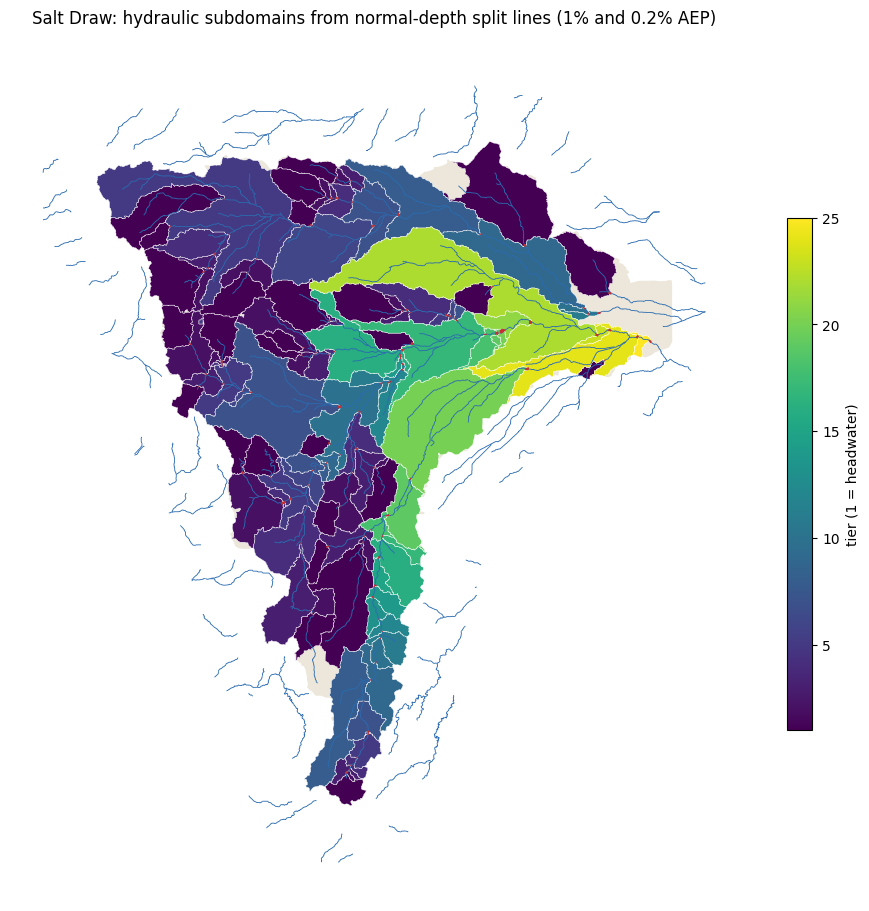

In [6]:
fig, ax = plt.subplots(figsize=(11, 9), constrained_layout=True)
tiers = subdomains[subdomains["subdomain_id"] != partition.remainder_id]
subdomains[subdomains["subdomain_id"] == partition.remainder_id].plot(ax=ax, color="#ECE7DA", edgecolor="none")
tiers.plot(ax=ax, column="tier", cmap="viridis", edgecolor="white", linewidth=0.3, legend=True,
           legend_kwds={"label": "tier (1 = headwater)", "shrink": 0.6})
streams[streams["contributing_area_sqmi"] >= 5].to_crs(subdomains.crs).plot(ax=ax, color="#2B6CB0", linewidth=0.6)
search.split_lines.plot(ax=ax, color="#C53030", linewidth=2.0)
ax.set_title("Salt Draw: hydraulic subdomains from normal-depth split lines (1% and 0.2% AEP)")
ax.set_axis_off()
fig.savefig(FIG_DIR / "01_subdomains.png", dpi=130)
plt.show()

## 5. Choose one headwater subdomain

A headwater subdomain (tier 1) has no subdomain upstream, so the parent's
rainfall is its only forcing. The choice is rule-based: no labels (in
particular no closed-edge leakage over 5% in either event), between 3 and
15 sq mi, and the lowest closed-edge exchange.

In [7]:
leak = [f"leak_fraction_{e}" for e in search.events]
pick = subdomains[(subdomains["tier"] == 1) & subdomains["labels"].apply(len).eq(0)
                  & subdomains["area_sqmi"].between(3, 15)].copy()
pick["worst_leak"] = pick[leak].max(axis=1)
pick = pick.sort_values("worst_leak")
display(pick[["subdomain_id", "cell_count", "area_sqmi", *leak]].head())
HEADWATER = pick["subdomain_id"].iloc[0]
line = search.split_lines.set_index("split_line_id").loc[int(HEADWATER)]
print(f"headwater {HEADWATER}: {int(pick.iloc[0]['cell_count']):,} cells, {pick.iloc[0]['area_sqmi']:.2f} sq mi; "
      f"outlet normal-depth slope {line['normal_depth_slope']:.4f} (TauDEM link slope {line['link_slope']:.4f})")

,subdomain_id,cell_count,area_sqmi,leak_fraction_1pct,leak_fraction_0_2pct
7,3081,2592,5.926358,0.042841,0.044098


headwater 3081: 2,592 cells, 5.93 sq mi; outlet normal-depth slope 0.0067 (TauDEM link slope 0.0157)


## 6. Author and validate the breakout

`plan_breakouts` writes nothing. It records the exact parent cells and the BC
lines, and runs `RasBreakout2D.preflight` on the parent. `apply_breakouts`
copies the parent project (without result HDFs) to `05_breakout`. There it
clones plan, geometry and unsteady file, removes the parent's BC lines from the
cloned geometry, cuts it to the parent's exact cells in HEC-RAS 6.4.1, and
writes the child's BC lines and their forcing.

Every line is then checked against its compiled external faces after a
preprocess; a failing line moves to its next placement variant. The child keeps
the parent's meteorology and initial conditions. It is held at the parent's
shortest time step (here 15 s), because a child must not out-step its parent.

In [8]:
breakout_plan = RasSubdomain.plan_breakouts(partition, "01", ras_object=parent, subdomain_ids=[HEADWATER])
display(breakout_plan.checks)
assert breakout_plan.is_ready
t0 = time.time()
breakouts = RasSubdomain.apply_breakouts(breakout_plan, BREAKOUT_DIR, overwrite_dest=True)
print(f"authored in {(time.time() - t0) / 60:.1f} min at a fixed "
      f"{breakouts.preparation[HEADWATER]['computation_interval']} step")
placement = breakouts.preparation[HEADWATER]["bc_placement"]
display(pd.DataFrame(placement["attempts"])[["attempt", "placements", "external_faces", "failing"]])
checks = RasSubdomain.validate_breakouts(breakouts)
display(checks)
assert not checks["blocking"].any()

2026-10-24 18:08:30 - ras_commander.RasBreakout2D - INFO - 2D breakout preflight sd_3081: ready=True, features=4102


,subdomain_id,check,passed,blocking,detail
0,*,parent_geometry_matches_search,True,False,SLDR_004.g02.hdf matches the searched mesh
1,3081,single_polygon_boundary,True,False,child boundary is Polygon with 0 holes
2,3081,has_outflow_boundary,True,False,1 outlet and 2 perimeter normal-depth lines
3,3081,breakout_preflight,True,False,ready


2026-10-24 18:08:33 - ras_commander.RasPrj - INFO - ras-commander v0.96.2 | An open-source project of CLB Engineering Corporation (https://clbengineering.com/) | Docs: https://rascommander.info | GitHub: https://github.com/gpt-cmdr/ras-commander


2026-10-24 18:08:33 - ras_commander.RasPrj - INFO - Project initialized: SLDR_004


2026-10-24 18:08:33 - ras_commander.RasPrj - INFO - Using HEC-RAS version 6.4.1


...

2026-10-24 18:11:28 - ras_commander.RasPreprocess - INFO - Starting HEC-RAS preprocessing for plan 08


2026-10-24 18:11:28 - ras_commander.RasBco - INFO - Monitoring SLDR_004.bco08 for 'Starting Unsteady Flow Computations' signal...


2026-10-24 18:11:47 - ras_commander.RasBco - INFO - Detected owned RasUnsteady.exe startup with complete preprocessing artifacts


2026-10-24 18:11:48 - ras_commander.RasPreprocess - WARNING - Could not establish preprocessing process ownership: Process name is unavailable


,subdomain_id,check,passed,blocking,detail
0,3081,bc_line_placement,True,False,1 placement pass(es)
1,3081,preprocess,True,False,geometry and event conditions written
2,3081,bc_line:Out_ND_3081,True,False,5 of 114 external faces
3,3081,bc_line:Edge_ND_1,True,False,98 of 114 external faces
4,3081,bc_line:Edge_ND_2,True,False,11 of 114 external faces


## 7. Run the headwater breakout (1% AEP)

In [9]:
runs = RasSubdomain.compute_subdomains(breakouts, max_workers=1, num_cores=NUM_CORES)
display(runs)
assert runs["success"].all()

2026-10-24 18:11:48 - ras_commander.RasCmdr - INFO - Filtered plans to execute: ['08']


2026-10-24 18:11:48 - ras_commander.RasCmdr - INFO - Adjusted max_workers to 1 based on the number of plans to compute: 1


2026-10-24 18:11:50 - ras_commander.RasCmdr - INFO - Prepared 1 worker folder(s) for parallel execution


2026-10-24 18:11:50 - ras_commander.ExecutionArtifacts - INFO - Removed plan 08 execution artifact: SLDR_004.bco08


2026-10-24 18:13:42 - ras_commander.RasCmdr - INFO - Plan 08 in worker 1: Successful


2026-10-24 18:13:42 - ras_commander.RasCmdr - INFO - Consolidating worker artifacts back to original project folder: Input


2026-10-24 18:13:45 - ras_commander.RasCmdr - INFO - Consolidated 3 worker artifact(s) to Input


2026-10-24 18:13:45 - ras_commander.RasCmdr - INFO - Execution results: 1/1 plan(s) successful


,subdomain_id,tier,plan_number,success,tier_wall_clock_s,plan_hdf_path
0,3081,1,08,True,117.295138,C:\Users\bill\AppData\Local\clb-gen3\scratch-s...


## 8. Compare with the parent

The breakout keeps the parent's cells, so every child cell is compared with the
same parent cell (matched by centre). Maximum WSE is compared over cells wet
above 0.1 ft in both models. The outlet hydrograph is the child's Normal Depth
outlet flow against the parent's native flow across the same faces. Both use
the parent's 1% AEP run (plan 01).

In [10]:
parent_1pct = parent_hdfs[0]
comparison = RasSubdomain.compare_to_parent(breakouts, parent_1pct)
display(comparison.T)

,0
subdomain_id,3081
status,compared
cells,2592
cells_matched_to_parent,2592
wet_cells_compared,2592
wse_diff_p50_ft,0.000488
wse_diff_p95_ft,0.01709
wse_diff_p99_ft,0.082739
wse_diff_max_ft,1.154297
wse_diff_mean_ft,0.001479


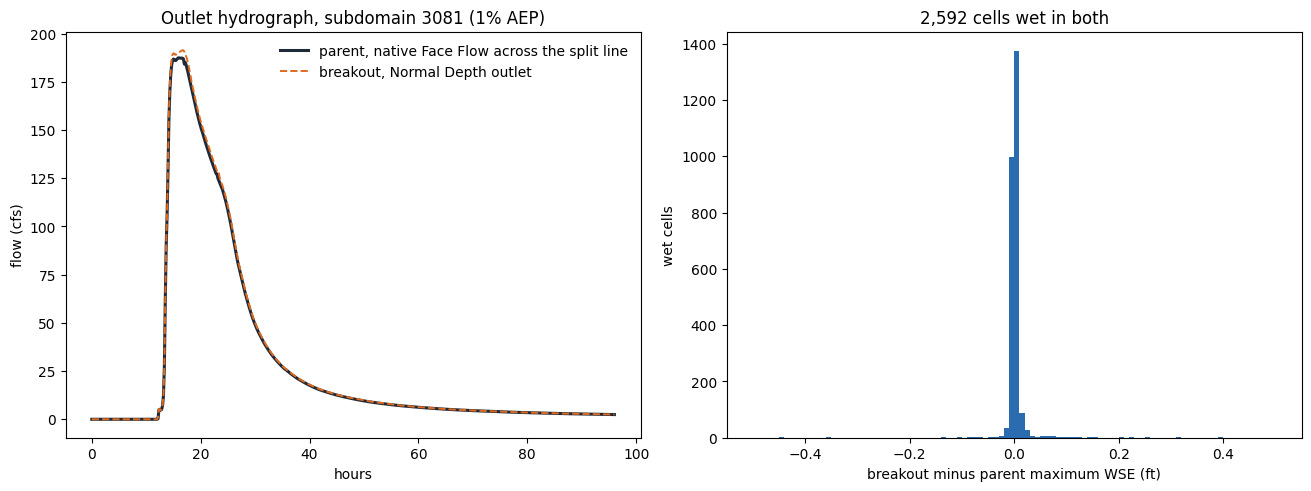

In [11]:
from scipy.spatial import cKDTree

from ras_commander.hdf import HdfResultsMesh
from ras_commander.subdomain._breakouts import _bc_flow
from ras_commander.subdomain._parent import EventReader

child_hdf = Path(runs["plan_hdf_path"].iloc[0])
outlet = search._context["lines"][int(HEADWATER)]
reader = EventReader(parent_1pct, "SLDR_004")
ids, flow = reader.series("Face Flow", outlet["faces"])
col = {int(f): i for i, f in enumerate(ids)}
parent_q = (flow[:, [col[int(f)] for f in outlet["faces"]]] * np.asarray(outlet["signs"])).sum(axis=1)
parent_h = reader.seconds() / 3600
child_h, child_q = _bc_flow(child_hdf, [f"Out_ND_{HEADWATER}"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
axes[0].plot(parent_h, parent_q, color="#1F2937", linewidth=2.2, label="parent, native Face Flow across the split line")
axes[0].plot(child_h, child_q, color="#DD6B20", linewidth=1.4, linestyle="--", label="breakout, Normal Depth outlet")
axes[0].set(xlabel="hours", ylabel="flow (cfs)", title=f"Outlet hydrograph, subdomain {HEADWATER} (1% AEP)")
axes[0].legend(frameon=False)

child_geometry = read_geometry(child_hdf, "SLDR_004")
_, idx = cKDTree(delivered_geometry.cell_center).query(child_geometry.cell_center)
cw = HdfResultsMesh.get_mesh_summary_values(child_hdf, "Maximum Water Surface").set_index("cell_id")["maximum_water_surface"]
pw = HdfResultsMesh.get_mesh_summary_values(parent_1pct, "Maximum Water Surface").set_index("cell_id")["maximum_water_surface"]
c_w = cw.reindex(np.arange(child_geometry.cell_count)).to_numpy()
p_w = pw.reindex(idx).to_numpy()
wet = (((c_w - child_geometry.cell_min_elevation) > 0.1)
       & ((p_w - delivered_geometry.cell_min_elevation[idx]) > 0.1))
axes[1].hist((c_w - p_w)[wet], bins=np.linspace(-0.5, 0.5, 101), color="#2B6CB0")
axes[1].set(xlabel="breakout minus parent maximum WSE (ft)", ylabel="wet cells",
            title=f"{int(wet.sum()):,} cells wet in both")
fig.savefig(FIG_DIR / "02_outlet_and_wse.png", dpi=130)
plt.show()

## Findings and limits

The tables above report; they do not pass or fail.

**The split.** In HEC-RAS 6.4.1 the search accepted 116 normal-depth split
lines that hold in both the 1% and 0.2% AEP events, nested into 25 tiers. On
the delivered mesh it scored 1,304 pour points (54,376 scored steps and
events) in about half an hour. Most candidates fail on outflow share or slope
ratio. A line placed where the channel is not yet carrying its catchment's
flow, or where the water surface slope departs from the bed slope, is rejected,
which is what a normal-depth boundary requires.

**The headwater breakout.** The chosen subdomain has 2,592 parent cells over
5.9 sq mi. Its closed edges exchanged under 5% of its outlet volume in both
events. The notebook cut it from the delivered mesh, preprocessed and ran it in
6.4.1, and held it at the parent's 15 s step. HEC-RAS attached its outlet and
both perimeter lines to the intended faces on the first placement. Against the
parent's 1% AEP run:

- **Maximum WSE:** within 0.0005 ft at the median, 0.017 ft at the 95th
  percentile and 0.083 ft at the 99th; the largest single difference is 1.15 ft.
  The wet extent is identical.
- **Outlet:** NSE 0.9994 against the parent's native flow across the same faces;
  peak +2.1%, volume +2.0%. The peak is a broad plateau, so the 40-minute
  peak-time offset marks a different point on the same plateau.

2D results are not reproducible to 0.01 ft over large areas even run to run,
so this is what a faithful project-level breakout looks like.

**Why the version and the time step matter.**

- **Version.** Running in the delivered version keeps the delivered mesh and
  its results comparable cell for cell. An earlier 6.6 run of this workflow
  first had to re-mesh the parent, because 6.6 rejects 48 cells with more than
  eight sides; it reached p95 0.018 ft and NSE 0.89.
- **Time step.** Holding the child at the parent's shortest step matters as
  much. With the inherited Courant-adaptive step, a headwater differed by up to
  3.1 ft (p95 0.67 ft): the parent's step is forced down by its most restrictive
  cells elsewhere in the HUC, which a small child never sees.

**What this does not show.** The tiered run of the whole HUC, with hydrograph
hand-off into downstream subdomains, is implemented (`compute_subdomains`) but
is not run here.

**Limits of this release:**

- feet models only;
- the exact-cell cut is qualified for HEC-RAS 6.4.1 and 6.6;
- subdomains with holes, more than one part, or a structure on a split line
  are refused at planning;
- the inflow hand-off rewrites the downstream inline hydrograph and
  preprocesses again.

**Roadmap:**

- an isolated subdomain around a project point or polygon, with its
  downstream and upstream boundary lines found automatically;
- the full-HUC tiered run with a parity table, on the fleet;
- interior subdomains with holes;
- SI units.
